In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.ensemble import RandomForestClassifier

# 선형 판별 분석(Linear Discriminant Analysis, LDA)

선형 판별 분석은 지도 학습적인 접근 방법을 통한 차원 축소 알고리즘으로 선형 판별 분석이라는 말의 뜻은 데이터 포인트가 속하는 클래스를 구분하는 판별 함수가 선형 형태의 함수라는 뜻이다.

데이터셋의 기존 공간으로 부터 집단간 분산과 집단내 분산의 비율을 최대화하는 기존 공간보다 `더 작은 차원의 공간`으로 원래 데이터를 투영시킴으로써 차원을 축소 한다. 즉, 데이터를 최대한 `분리`해주는 기능을 한다.

선형 판별 분석은 크게 3단계 과정을 거친다.  
① 집단간 거리를 계산한다. 이를 집단간 분산이라고 한다.  
② 각 집단의 평균과 각 데이터 포인트의 거리를 계산한다. 이를 집단내 분산이라고 한다.  
③ 기존 데이터셋의 공간보다 더 작은 차원의 공간을 만드는 것이다. 이 공간은 집단간 분산을 최대화하고 집단내 분산을 최소로 하는 공간이어야 한다.

# 차원을 축소하기 전과 차원을 축소한 후 정확도를 비교한다.

## 와인 데이터를 선형 판별 분석 알고리즘에 사용할 데이터를 준비한다.

In [2]:
raw_data = datasets.load_wine()

xData = raw_data.data
yData = raw_data.target

x_train, x_test, y_train, y_test = train_test_split(xData, yData, random_state=1)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## 선형 판별 분석 모델을 만들고 학습 시킨다.

선형 판별 분석을 알고리즘을 사용하기 위해 LinearDiscriminantAnalysis를 import 한다.

In [3]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

n_components에 축소하려는 차원 크기를 지정해서 선형 판별 분석 모델을 만들고 학습한 후 적용시킨다.

`주의 사항`  
n_components에 사용 가능한 값은 `min(피처 개수, 클래스 개수 - 1)보다 큰 값을 지정할 수 없다.`  
와인 데이터의 피처는 13개이고 클래스는 3개이므로 n_components는 min(13, 3 - 1)의 결과인 2보다 큰 값을 지정하면 에러가 발생된다.

In [21]:
model = LinearDiscriminantAnalysis(n_components=2)
# 주성분 분석과 커널 주성분 분석은 비지도 학습적인 방법이므로 차원 축소 모델을 학습시킬 때 학습 데이터의 피처만 넘겨서 학습시켰지만 선형 판별 분석은
# 지도 학습적인 방법이므로 학습 데이터의 피처와 학습 데이터의 피처에 따른 레이블까지 넘겨서 학습시킨다.
# model.fit(x_train, y_train)
# x_train_lda = model.transform(x_train)
x_train_lda = model.fit_transform(x_train, y_train)
x_test_lda = model.transform(x_test)
print(x_train.shape, x_train_lda.shape, x_test.shape, x_test_lda.shape)

(133, 13) (133, 2) (45, 13) (45, 2)


## 레이블 종류, 상수항, 가중 벡터를 확인한다.

classes_ 속성으로 선형 판별 분석 모델을 학습시킬때 사용된 레이블 종류를 얻어올 수 있다.

In [8]:
print(model.classes_)

[0 1 2]


intercept_ 속성으로 차원 축소에 사용된 상수항을 얻어올 수 있다.

In [9]:
print(model.intercept_)

[ -9.68249758  -3.74337099 -10.87003773]


coef_ 속성으로 차원 축소에 사용된 가중 벡터를 얻어올 수 있다.

In [10]:
print(model.coef_)

[[ 2.1641846   0.34960415  1.64466034 -2.6884109  -0.03022561 -1.96902415
   5.56157521  0.30838124 -0.68263176 -2.13770621  0.54805318  3.13073463
   5.57902776]
 [-1.21447124 -0.99888395 -1.67891952  1.2237471   0.22625145  0.30375348
   1.16346151  0.44388371  0.34196434 -1.6117693   0.5784938  -0.1813972
  -2.402758  ]
 [-0.60921373  1.04226219  0.61133106  1.16164483 -0.28890336  1.69282374
  -7.65398697 -0.96350924  0.25057442  4.59688151 -1.41339068 -3.12012292
  -2.60503174]]


## 선형 판별 분석을 통해 차원 축소된 데이터 시각화

In [11]:
df = pd.DataFrame(x_train_lda, columns=['x', 'y'])
df['label'] = y_train
df

,x,y,label
0,-2.592701,-0.508985,0
1,-0.653427,-2.194654,1
2,-4.027584,1.640188,0
3,-6.024549,3.922633,0
4,-4.094279,2.362495,0
...,...,...,...
128,3.560260,0.445735,2
129,4.508654,0.496923,2
130,0.646597,-1.704028,1
131,2.468208,1.182040,2


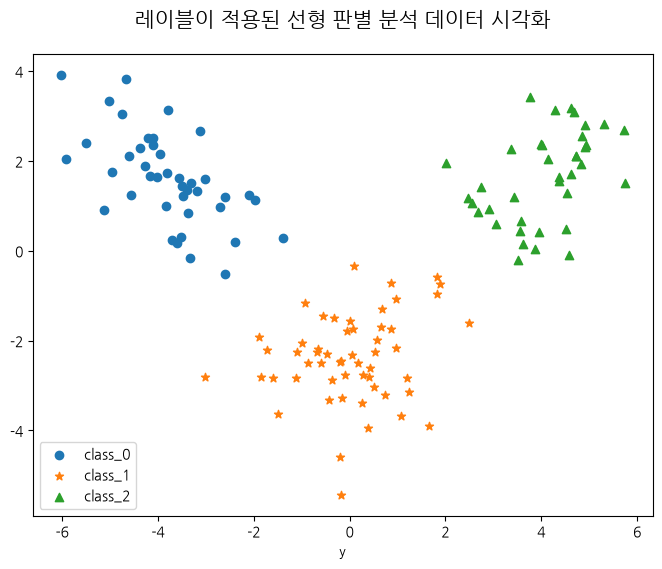

In [12]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for i in range(len(raw_data.target_names)):
    df_index = df[df.label == i]
    label = raw_data.target_names[i]
    plt.scatter(x=df_index.x, y=df_index.y, label=label, marker=markers[i])

plt.title('레이블이 적용된 선형 판별 분석 데이터 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.xlabel('y')
plt.legend()
plt.show()

## 선형 판별 분석 적용 전, 후 데이터로 랜덤 포레스트 모델로 학습시키고 예측 후 평가한다.

선형 판별 분석 전 데이터 학습 및 예측, 평가

In [13]:
model = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train, y_train)
predict = model.predict(x_test)
print(predict)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 2 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [14]:
classification = classification_report(y_test, predict, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.94      0.97        17
     class_2       1.00      1.00      1.00        10

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



선형 판별 분석 후 데이터 학습 및 예측, 평가

In [15]:
model_lda = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train_lda, y_train)
predict_lda = model_lda.predict(x_test_lda)
print(predict_lda)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 2 1 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [16]:
classification = classification_report(y_test, predict_lda, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        17
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

